# Operations DMAIC Case Study: Field-Service Tool Management & Loading Efficiency

**Privacy note:** This case study has been anonymized. The company name, owner name,
and employee names have been removed, and the business's location and calendar dates
have been generalized for public portfolio use. Quantified operational results
(percentages, hours, dollar estimates) are preserved from the original engagement, since
they represent the analytical content of this project and do not, on their own, identify
the business. See `NOTES.md` for the full list of what was changed.

A DMAIC case study about tool preparation at a small, two-person field-service business. The notebook rebuilds charts from sanitized summary tables. The original observation logs are not included, so the reported before-and-after results cannot be independently recalculated here.


## Define

**Business context:** the Company is a small regional landscaping and tree-service
business (two field workers, two vehicles) providing tree trimming/removal, outdoor
lighting installation, and general landscaping services in a mid-sized U.S. metro area.

**Problem statement:** the Company had no standardized tool management or pre-job
preparation process. Tools were stored without organization, job preparation relied
entirely on memory, and forgotten tools caused frequent field delays. The project used a DMAIC framework. The source report describes all five 5S practices, including a post-job cleaning and tool-return routine under Shine.

**Goal statement:** reduce wasted field time, materials cost, and job execution errors
by standardizing pre-job planning and tool loading without adding software, headcount,
or capital investment. The public goal statement does not set a numeric target or deadline.

**Project scope:**
- Tool storage and loading process at the operating base
- Client estimate intake and remote job commitment protocol
- Worker scheduling and synchronized start times
- Materials and supply management by job type


## Measure

Baselines were established using attribute-based observation (checklist present/absent,
loading time, tool correctness, gate-code availability, start-time alignment), collected
through direct observation, an owner interview, and a review of truck/storage contents.
A formal Gauge R&R study wasn't appropriate given the attribute- and time-based
measurement approach; consistency was instead ensured by defining each metric in writing
before data collection began and using the same paper form for every observation.

### Data Loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrow
import os

plt.rcParams["figure.dpi"] = 110
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)

kpi = pd.read_csv("data/kpi_summary.csv")
cost = pd.read_csv("data/annual_cost_impact.csv")
kpi

,KPI,Baseline,Target_Or_Result,Unit,Improvement_Pct
0,Timed Tool Loading (Controlled Comparison),10.38,5.57,minutes,46.3
1,Forgotten Tool Incidents per Week (Estimated),3.50,0.50,incidents,85.7
2,Estimated Defect Rate per Departure,23.30,3.30,percent,85.8


In [2]:
cost

,Root_Cause_Category,Estimated_Annual_Cost_USD,Basis
0,Unpaid early-arrival loading labor,3375,45 min/job x ~250 jobs/yr = 187.5 hrs/yr x $18...
1,Wasted remote-estimate trips,2178,Midpoint of $1452-$2904/yr range (confirmed $1...
2,Forgotten-tool field delays,2700,Midpoint of 100-200 hrs/yr field delay x $18/h...
3,Uncontrolled tool loading time,1404,78 hrs/yr excess loading time x $18/hr labor rate
4,Duplicate tool/material purchases,340,20+ duplicate chainsaw chains confirmed at $17...


### Data Quality Check

Both files are small, manually compiled summary tables (not raw transactional data), so
the checks here are simple completeness and range checks rather than a large-scale
missing-value/duplicate audit.


In [3]:
print("KPI summary: missing values:", kpi.isna().sum().sum(), " | rows:", len(kpi))
print("Cost impact: missing values:", cost.isna().sum().sum(), " | rows:", len(cost))
print()
print("KPI improvement range check (all should be between 0-100%):")
print(kpi["Improvement_Pct"].between(0, 100).all())

KPI summary: missing values: 0  | rows: 3
Cost impact: missing values: 0  | rows: 5

KPI improvement range check (all should be between 0-100%):
True


### Estimated defect rate and sigma convention

The source report estimates about 15 job departures per week and 3.5 forgotten-tool incidents per week before the change, then 0.5 afterward. The resulting 23.3% and 3.3% rates assume each incident is a distinct departure-level defect. The source report includes a blank weekly tracking form, but no completed log or departure-level denominator was found in the archived project materials; multiple incidents on one departure have not been ruled out.

The reported sigma estimates of about 2.2 and 3.3 are numerically consistent with a conventional 1.5-sigma shift applied to these rates, but the source report does not state its convention. They are estimates, not validated process capability figures.


In [4]:
from statistics import NormalDist

baseline_defect_rate = 23.3  # percent; estimated from 3.5 incidents / ~15 departures per week
target_defect_rate = 3.3     # percent; estimated from 0.5 incidents / ~15 departures per week
sigma_shift = 1.5           # inferred from source-reported estimates; the source does not state the convention

def estimate_sigma(rate_pct):
    yield_rate = 1 - rate_pct / 100
    return NormalDist().inv_cdf(yield_rate) + sigma_shift

baseline_dpmo = baseline_defect_rate / 100 * 1_000_000
target_dpmo = target_defect_rate / 100 * 1_000_000
print(f"Baseline estimated DPMO: {baseline_dpmo:,.0f}; shifted sigma: {estimate_sigma(baseline_defect_rate):.1f}")
print(f"After estimated DPMO:    {target_dpmo:,.0f}; shifted sigma: {estimate_sigma(target_defect_rate):.1f}")
print("Assumption: one distinct defect opportunity per departure; incident counts and denominator were not independently verified.")


Baseline estimated DPMO: 233,000; shifted sigma: 2.2
After estimated DPMO:    33,000; shifted sigma: 3.3
Assumption: one distinct defect opportunity per departure; incident counts and denominator were not independently verified.


### Process timeline

The engagement ran as a sequential-but-overlapping DMAIC cycle over roughly four months.


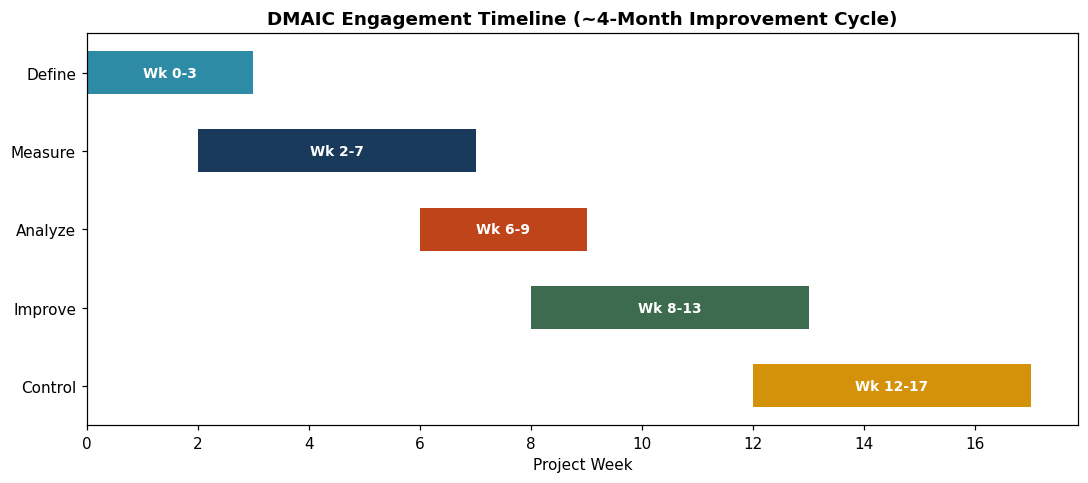

In [5]:
phases = [
    ("Define",  0, 3),
    ("Measure", 2, 7),
    ("Analyze", 6, 9),
    ("Improve", 8, 13),
    ("Control", 12, 17),
]
colors = ["#2E8BA5", "#1A3A5C", "#C0441A", "#3D6B4F", "#D4920A"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (name, start, end) in enumerate(phases):
    ax.barh(name, end - start, left=start, color=colors[i], height=0.55)
    ax.text(start + (end - start) / 2, i, f"Wk {start}-{end}", ha="center", va="center",
            color="white", fontweight="bold", fontsize=9)
ax.set_xlabel("Project Week")
ax.set_title("DMAIC Engagement Timeline (~4-Month Improvement Cycle)", fontweight="bold")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/process-timeline.png", dpi=150)
plt.show()

## Analyze

The fishbone, 5 Whys, and cost ranking were used to organize the observed failure points and identify likely process causes. The available summary does not independently rule out demand, staffing, or equipment factors, so the root-cause categories should be read as the team's analysis rather than a tested exclusion of alternatives.

### Root cause categories (fishbone analysis)


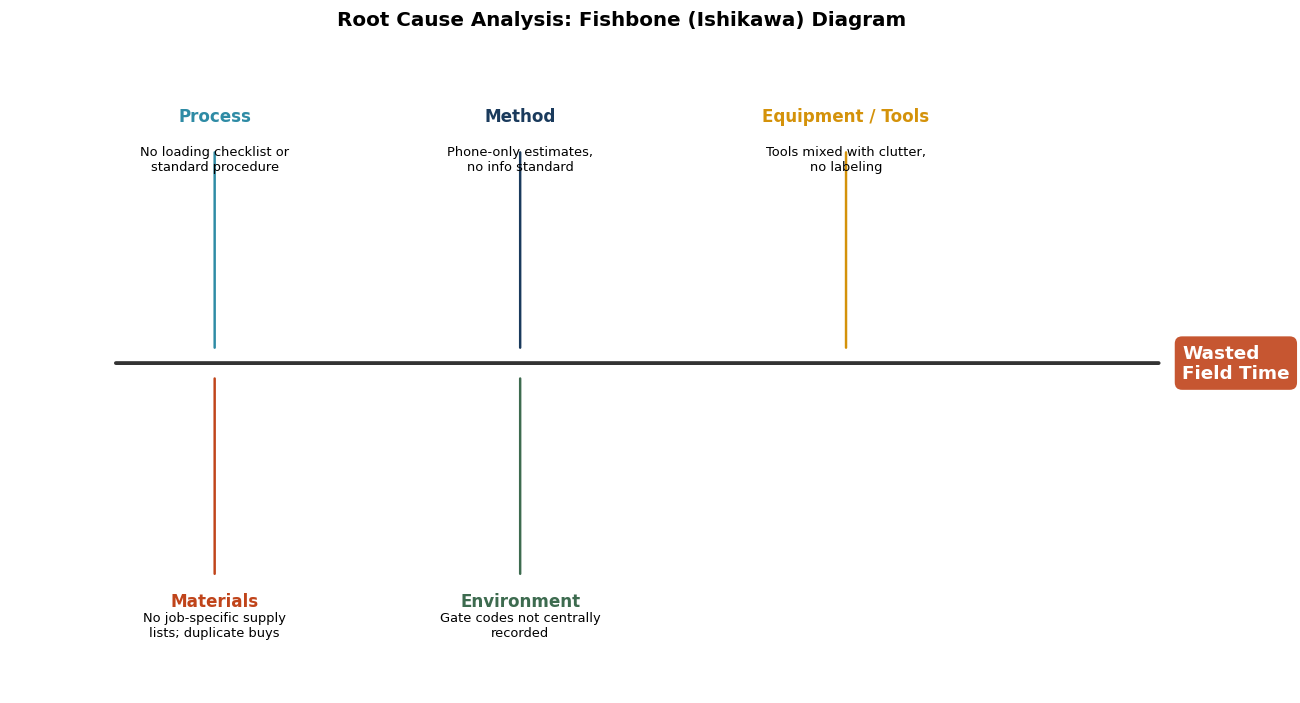

In [6]:
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

# spine
ax.annotate("", xy=(11.3, 4), xytext=(1, 4), arrowprops=dict(arrowstyle="-", lw=2.5, color="#333"))
ax.text(11.5, 4, "Wasted\nField Time", fontsize=12, fontweight="bold", va="center",
        bbox=dict(boxstyle="round,pad=0.4", fc="#C0441A", ec="none", alpha=0.9), color="white")

causes = {
    "Process":   ("No loading checklist or\nstandard procedure", 2.0, 6.6, 1),
    "Method":    ("Phone-only estimates,\nno info standard", 5.0, 6.6, 1),
    "Materials": ("No job-specific supply\nlists; duplicate buys", 2.0, 1.4, -1),
    "Environment": ("Gate codes not centrally\nrecorded", 5.0, 1.4, -1),
    "Equipment / Tools": ("Tools mixed with clutter,\nno labeling", 8.2, 6.6, 1),
}

for label, (desc, x, y, direction) in causes.items():
    branch_x_end = x
    ax.annotate("", xy=(branch_x_end, 4 + 0.15*direction), xytext=(x, y),
                arrowprops=dict(arrowstyle="-", lw=1.6, color=colors[list(causes).index(label) % len(colors)]))
    ax.text(x, y + (0.35 if direction > 0 else -0.35), label, fontsize=11, fontweight="bold",
            ha="center", color=colors[list(causes).index(label) % len(colors)])
    ax.text(x, y + (0.05 if direction > 0 else -0.75) , desc, fontsize=8.5, ha="center", va="top" if direction>0 else "bottom")

ax.set_title("Root Cause Analysis: Fishbone (Ishikawa) Diagram", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/root-cause-fishbone.png", dpi=150)
plt.show()

### cost ranking by estimated annual cost

The chart ranks rough annual estimates, based on reported frequencies and an $18/hour labor rate. Some categories may overlap, so their values should not be added as verified savings. The source report also gives inconsistent annual dollar estimates for unpaid loading time: the unrounded calculation is $3,375, while its benefits table lists $1,125.


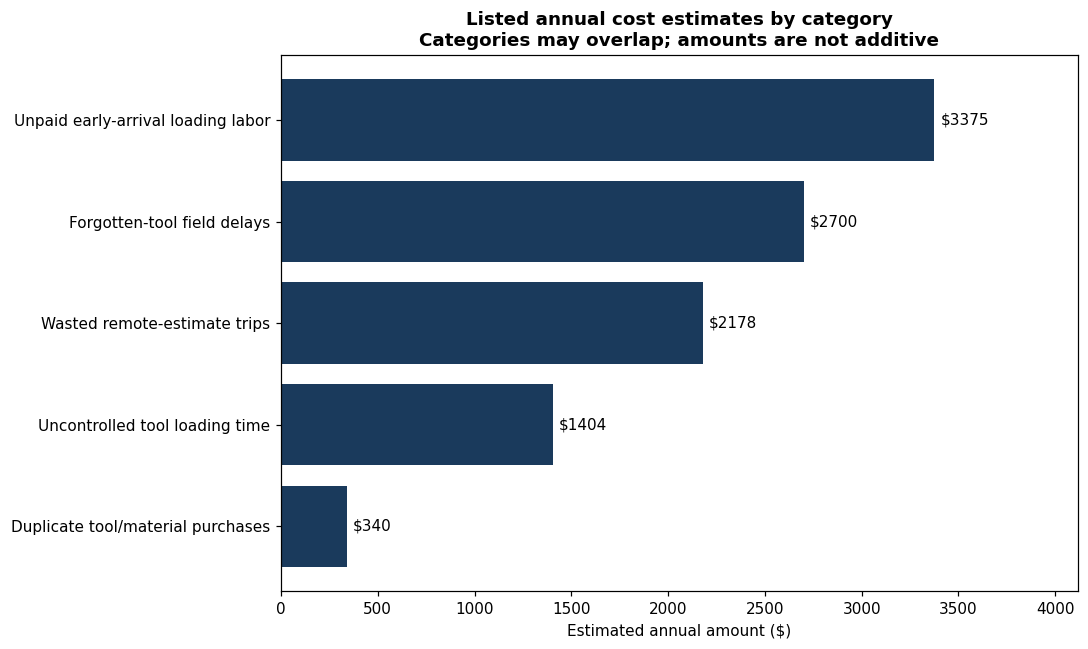

In [7]:
cost_sorted = cost.sort_values("Estimated_Annual_Cost_USD", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(cost_sorted["Root_Cause_Category"], cost_sorted["Estimated_Annual_Cost_USD"], color="#1A3A5C")
ax.set_xlabel("Estimated annual amount ($)")
ax.set_title("Listed annual cost estimates by category\nCategories may overlap; amounts are not additive", fontweight="bold")
ax.bar_label(bars, fmt="$%.0f", padding=4)
ax.set_xlim(0, cost_sorted["Estimated_Annual_Cost_USD"].max() * 1.22)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/issue-frequency-pareto.png", dpi=150)
plt.show()


## Improve

All solutions were constrained to work within a low-tech, two-person operation: no
scheduling software, no new hires, no capital investment. Alternatives considered and
rejected included field-service scheduling software (added cost and workflow overhead
not aligned with the owner's preference), a full inventory management system
(overkill for a two-person team's job-readiness problem), and adding a vehicle or
staff (would have scaled the existing waste rather than fixing it).

**What was implemented (5S):** The source report describes all five practices.
- **Sort**: separated tools from clutter across the storage area; this pass is what
  surfaced the duplicate tool inventory.
- **Set in Order**: color-coded tool labeling by job type, labeled storage zones,
  laminated visual reference guides.
- **Shine**: post-job cleaning and returning tools to their assigned places.
- **Standardize**: two vehicle binders (one per truck) with job-specific checklists, an
  estimate checklist, and a gate-code reference sheet.
- **Sustain**: in-person training on the full system for both workers.

A standardized estimate protocol was also introduced: any job more than ~45 minutes from
base now requires a photo or video from the client before a commitment is made, directly
targeting the wasted-trip root cause.

### Reported before / after measures


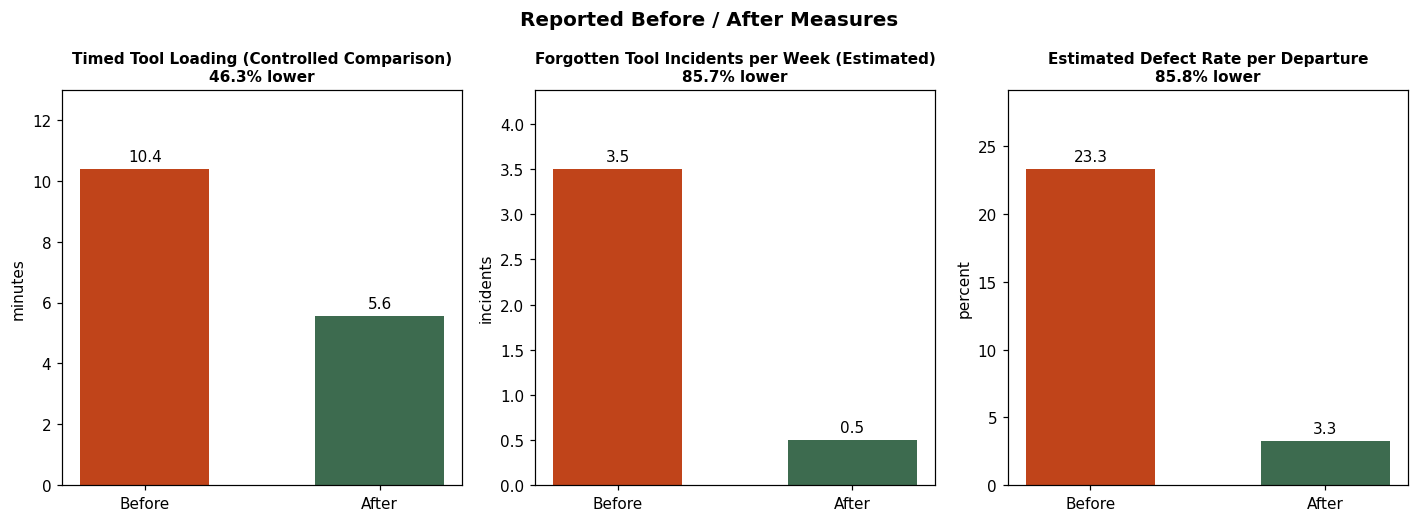

In [8]:
kpi_plot = kpi.set_index("KPI")
fig, axes = plt.subplots(1, len(kpi_plot), figsize=(13, 4.8))

for ax, (idx, row) in zip(axes, kpi_plot.iterrows()):
    bars = ax.bar(["Before", "After"], [row["Baseline"], row["Target_Or_Result"]],
                  color=["#C0441A", "#3D6B4F"], width=0.55)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_title(f"{idx}\n{row['Improvement_Pct']:.1f}% lower", fontsize=10, fontweight="bold")
    ax.set_ylabel(row["Unit"])
    ax.set_ylim(0, max(row["Baseline"], row["Target_Or_Result"]) * 1.25)

fig.suptitle("Reported Before / After Measures", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/before-after-kpi-comparison.png", dpi=150)
plt.show()


## Control

The report lists eight controls with methods and frequencies, including a weekly incident log. It also includes a blank tracking form, but no completed log was found in the archived project materials. The control plan does not name an owner, set trigger limits, or describe a response when a check fails. The listed controls therefore do not show whether they operated or kept results on target.


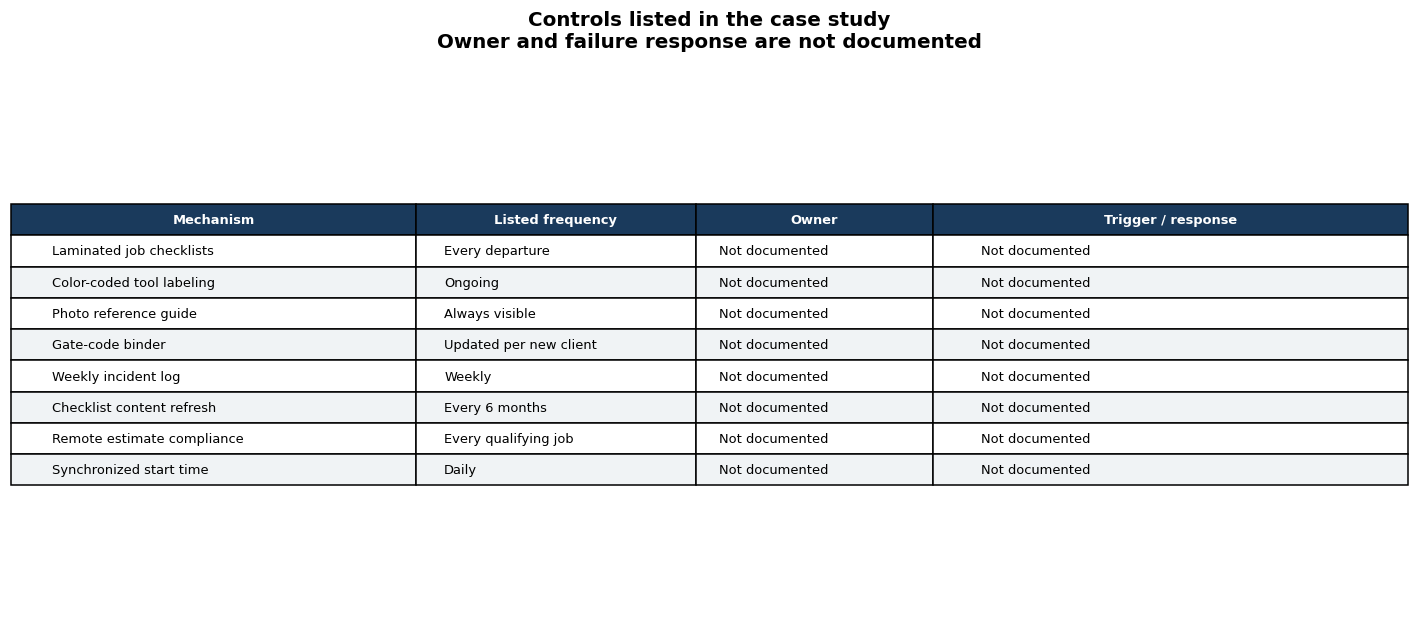

In [9]:
control_mechanisms = pd.DataFrame({
    "Mechanism": [
        "Laminated job checklists", "Color-coded tool labeling", "Photo reference guide",
        "Gate-code binder", "Weekly incident log", "Checklist content refresh",
        "Remote estimate compliance", "Synchronized start time"
    ],
    "Listed frequency": [
        "Every departure", "Ongoing", "Always visible", "Updated per new client",
        "Weekly", "Every 6 months", "Every qualifying job", "Daily"
    ],
    "Owner": ["Not documented"] * 8,
    "Trigger / response": ["Not documented"] * 8
})

fig, ax = plt.subplots(figsize=(13, 5.8))
ax.axis("off")
table = ax.table(
    cellText=control_mechanisms.values,
    colLabels=control_mechanisms.columns,
    colWidths=[0.29, 0.20, 0.17, 0.34],
    cellLoc="left", loc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 1.55)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#1A3A5C")
    elif row % 2 == 0:
        cell.set_facecolor("#F0F3F5")
ax.set_title("Controls listed in the case study\nOwner and failure response are not documented",
             fontweight="bold", fontsize=13, pad=18)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/control-plan-summary.png", dpi=160, bbox_inches="tight")
plt.show()


## Findings

- In the reported timed comparison, loading took 10:23 before and 5:34 after, a 46% reduction. The source describes this as a controlled timed test, not a repeated sample, and separately reports typical morning loading at 20 to 30 minutes.
- The reported forgotten-tool frequency moved from an estimated 3 to 4 incidents per week to 0 to 1 (averages of 3.5 and 0.5). The 23.3% and 3.3% rates assume about 15 departures per week and one defect opportunity per departure. The report includes a blank weekly tracking form, but no completed log or departure-level denominator was found in the archived project materials; multiple incidents on one departure have not been ruled out.
- Sorting surfaced 20+ duplicate chainsaw chains valued at $340 or more in the source report. This is identified inventory, not verified cash savings.
- The source estimates unpaid early-arrival loading at about 188 hours per year. Its report gives inconsistent dollar estimates ($3,375 in the calculation and $1,125 in the benefits table), so the financial impact needs reconciliation.
- The reported sigma levels (about 2.2 and 3.3) are numerically consistent with a 1.5-sigma shift applied to the estimated departure-level rates, but the source does not state the convention. They are not validated process capability results.


## Recommendations

- Record each departure, loading time, checklist completion, forgotten-tool event, access delay, and any return trip. Count both incidents and distinct departures with at least one incident.
- Collect the same measures for a defined baseline and for at least four to six weeks after the changes. Report sample sizes and dates with any before-and-after comparison.
- Reconcile the unpaid-loading estimate and keep cost categories separate until overlap is resolved. Distinguish identified inventory from cash savings and projected costs from realized savings.
- Complete the control plan with an owner, check frequency, target or trigger, and response for each measure.
- The source report describes a post-job cleaning and tool-return routine under Shine; the public summary now includes it.


## Limitations

- This is an anonymized case study based on a real small-business engagement. Identifying details were removed or generalized; see `NOTES.md`.
- Measurement used manual stopwatch observations, self-report, and receipts. A blank weekly tracking form appears in the source report, but no completed underlying logs, sample sizes, or post-change observation window were found in the archived project materials, so the reported changes cannot be independently recomputed here.
- The estimated defect rate assumes about 15 weekly departures and one defect opportunity per departure. The project summary does not establish that each incident occurred on a different departure.
- The $18/hour rate and projected annual frequencies were not independently verified. The cost categories may overlap. The CSV uses the source calculation of $3,375 based on 187.5 hours before rounding; a separate source table lists $1,125, which remains unreconciled.
- The reported sigma estimates are numerically consistent with a 1.5-sigma shift, but the source does not state the convention. They should not be presented as validated capability measures.
- Results are from a limited post-implementation period. Sustained performance across a full year has not been established.
- The original records and photographs are not in this public package; calculations here use sanitized summary data.
